# 03. Customer Segmentation via Clustering

This notebook answers the question left open by `02_rfm.ipynb`: do natural
customer segments exist beyond what simple RFM quartiles already show?

We cluster households on their Recency, Frequency, and Monetary values using
K-means, with the number of clusters (k) chosen via the elbow method and
silhouette score, not assumed in advance, and not cross-validated with
LOOCV, which doesn't apply to unsupervised learning without a target
variable (a carryover technique from a prior project that wouldn't be
methodologically justified here).

Two design decisions, made explicit before any code:
- **Scaling:** `recency`, `frequency`, and `monetary` live on very
  different scales (days vs. basket counts vs. dollars). K-means uses
  Euclidean distance, so without scaling, `monetary` would dominate the
  distance calculation purely because its raw numbers are larger, not
  because it's more important. We use `StandardScaler` (z-score
  standardization), the standard choice for K-means.
- **Outliers:** rather than deciding upfront whether to remove the 147
  frequency outliers and 127 monetary outliers flagged in `02_rfm.ipynb`
  (Section 6), we run the full clustering pipeline twice, once with the
  full 2,500 households, once excluding outliers, and compare. This
  follows directly from that notebook's finding that the top monetary
  outliers looked like genuine high-value customers, not errors: if
  K-means gives them their own coherent segment, that's a meaningful
  result, not noise to discard by default.

## 1. Environment Setup

We load `rfm_household` directly from PostgreSQL, the table persisted at
the end of `02_rfm.ipynb`, rather than depending on that notebook having
run in the same session. The cell also confirms `rfm_household` actually has rows before proceeding, and orders the query by `household_key` explicitly: K-means' random initialization depends on the order rows arrive in, so a `SELECT *` without `ORDER BY` would leave that order at the mercy of PostgreSQL's internal storage, undermining the reproducibility `random_state=42` is meant to guarantee later in this notebook.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # Workaround for Intel/LLVM OpenMP conflict (KMeans crashes without this)

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import matplotlib.pyplot as plt

load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

required = {"DB_HOST": DB_HOST, "DB_PORT": DB_PORT, "DB_NAME": DB_NAME,
            "DB_USER": DB_USER, "DB_PASSWORD": DB_PASSWORD}
missing = [name for name, value in required.items() if not value]
if missing:
    raise EnvironmentError(f"Missing variables in .env: {missing}")

engine = create_engine(
    URL.create(
        drivername="postgresql+psycopg2",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=int(DB_PORT),
        database=DB_NAME,
    )
)

rfm = pd.read_sql(text("SELECT * FROM rfm_household ORDER BY household_key;"), engine)

if len(rfm) == 0:
    raise RuntimeError(
        "rfm_household is empty. Run 02_rfm.ipynb before this notebook."
    )

print(f"Loaded {len(rfm)} households from rfm_household.")
rfm.head()

Loaded 2500 households from rfm_household.


,household_key,reference_day,last_purchase_day,recency,frequency,monetary,avg_ticket,r_score,f_score,m_score,rfm_score,segment
0,1,711,706,5,85,4330.16,50.94,3,3,4,334,Loyal Customers
1,2,711,668,43,45,1954.34,43.43,1,2,3,123,Other
2,3,711,703,8,47,2653.21,56.45,3,2,3,323,Other
3,4,711,627,84,30,1200.11,40.00,1,1,2,112,Lost
4,5,711,703,8,40,779.06,19.48,3,2,2,322,Other


2,500 households loaded from `rfm_household`, with all 12 columns intact
(raw RFM, scores, `rfm_score`, and `segment` from `02_rfm.ipynb`),
confirming the notebook can run independently from a fresh kernel, without
needing `02_rfm.ipynb` to have executed in the same session.

## 2. Feature Preparation and Scaling

Clustering uses only `recency`, `frequency`, and `monetary`, the raw RFM
values, not the 1-5 quintile scores. Scores were designed for human-readable
segmentation (Section 5 of `02_rfm.ipynb`), but compress real variation into
5 buckets; clustering should work on the actual underlying values to detect
structure the scores might flatten out. `avg_ticket` is deliberately
excluded, it's a derived ratio of `monetary`/`frequency`, not an
independent signal, and including it alongside its own components would let
that relationship implicitly double-count in the distance calculation.

We prepare two versions of the feature set: the full 2,500 households, and
one excluding the outliers flagged in `02_rfm.ipynb` (Section 6), 147 on
`frequency`, 127 on `monetary`, with some overlap between the two sets.

In [2]:
features = ["recency", "frequency", "monetary"]

X_full = rfm[features].copy()

def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

freq_lower, freq_upper = iqr_bounds(rfm["frequency"])
mon_lower, mon_upper = iqr_bounds(rfm["monetary"])

is_outlier = (
    (rfm["frequency"] < freq_lower) | (rfm["frequency"] > freq_upper) |
    (rfm["monetary"] < mon_lower) | (rfm["monetary"] > mon_upper)
)

rfm_no_outliers = rfm.loc[~is_outlier].copy()
X_no_outliers = rfm_no_outliers[features].copy()

print(f"Full dataset: {len(X_full)} households")
print(f"Excluding outliers: {len(X_no_outliers)} households ({is_outlier.sum()} removed)")

scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_full)

scaler_no_outliers = StandardScaler()
X_no_outliers_scaled = scaler_no_outliers.fit_transform(X_no_outliers)

print(f"\nMean after scaling (should be ~0): {X_full_scaled.mean(axis=0).round(3)}")
print(f"Std after scaling (should be ~1): {X_full_scaled.std(axis=0).round(3)}")

Full dataset: 2500 households
Excluding outliers: 2292 households (208 removed)

Mean after scaling (should be ~0): [-0. -0.  0.]
Std after scaling (should be ~1): [1. 1. 1.]


2,292 households remain after excluding outliers (208 removed), fewer than
the raw 147+127=274 sum from Section 6 of `02_rfm.ipynb`, confirming real
overlap: 66 households were outliers on both `frequency` and `monetary`
simultaneously, not two disjoint groups.

Scaling confirmed correct on the full dataset: mean ~0, standard deviation
~1 across all three features. Both scaled feature sets (`X_full_scaled`,
`X_no_outliers_scaled`) are ready for K-means.

Scaling addresses *scale* (days vs. baskets vs. dollars), but not *skew*: `recency`, `frequency`, and `monetary` are all right-skewed (`02_rfm.ipynb`, Section 3.1), and `StandardScaler` only rescales variance, it doesn't pull in the long tail. That is a large part of why Section 4 finds K-means so sensitive to the extreme values below: standardization alone does not protect against it. An alternative would be to log-transform `frequency` and `monetary` before scaling, or use a `RobustScaler` based on the median and IQR instead of the mean and standard deviation. Either would likely reduce (not eliminate) the boundary-shifting effect demonstrated below, at the cost of clustering in a space that no longer maps directly to dollars and basket counts. The dual-run design adopted here keeps that direct, business-readable interpretation and treats the outlier sensitivity as a finding to document and act on (Section 6), rather than a distortion to transform away; it is worth being explicit that this is a choice, not the only valid one.

Before fitting anything, it is also worth checking how correlated the three raw features are: K-means treats each scaled dimension as an independent axis, but if two of the three are strongly correlated, the "3-dimensional" clustering is effectively picking up fewer independent axes of real variation.

In [3]:
correlation_matrix = rfm[["recency", "frequency", "monetary"]].corr().round(3)
correlation_matrix

,recency,frequency,monetary
recency,1.000,-0.235,-0.239
frequency,-0.235,1.000,0.703
monetary,-0.239,0.703,1.000


A strong positive correlation between `frequency` and `monetary` is expected in retail data (buying more often tends to mean spending more in total), and would mean the clustering is leaning heavily on what is close to a single combined "value" axis plus `recency` as a second axis, rather than three equally independent dimensions. This doesn't invalidate the clustering, K-means is still free to use whatever structure is actually there, but it is a useful fact to have on hand when interpreting why three clusters separate cleanly along what will turn out to be mostly a value gradient (Section 4).

## 3. Choosing k: Elbow Method and Silhouette Score

We don't assume a number of clusters, k is chosen using two complementary
diagnostics, run on both feature sets (full and outlier-excluded):

- **Elbow method**: inertia (within-cluster sum of squared distances) as k
  increases. Inertia always decreases as k grows, so we look for the point
  where the rate of decrease flattens, adding more clusters past that point
  buys little additional structure.
- **Silhouette score**: measures how well-separated clusters are (ranges
  from -1 to 1; higher is better). Unlike inertia, this doesn't always
  favor more clusters, so it helps cross-check what the elbow suggests.

Both are computed for k = 2 through 10.

Silhouette scores (full): [0.5255, 0.5764, 0.445, 0.4628, 0.4313, 0.3785, 0.3736, 0.3918, 0.3651]
Silhouette scores (no outliers): [0.4633, 0.5034, 0.4024, 0.4167, 0.4038, 0.3631, 0.3671, 0.3585, 0.3301]


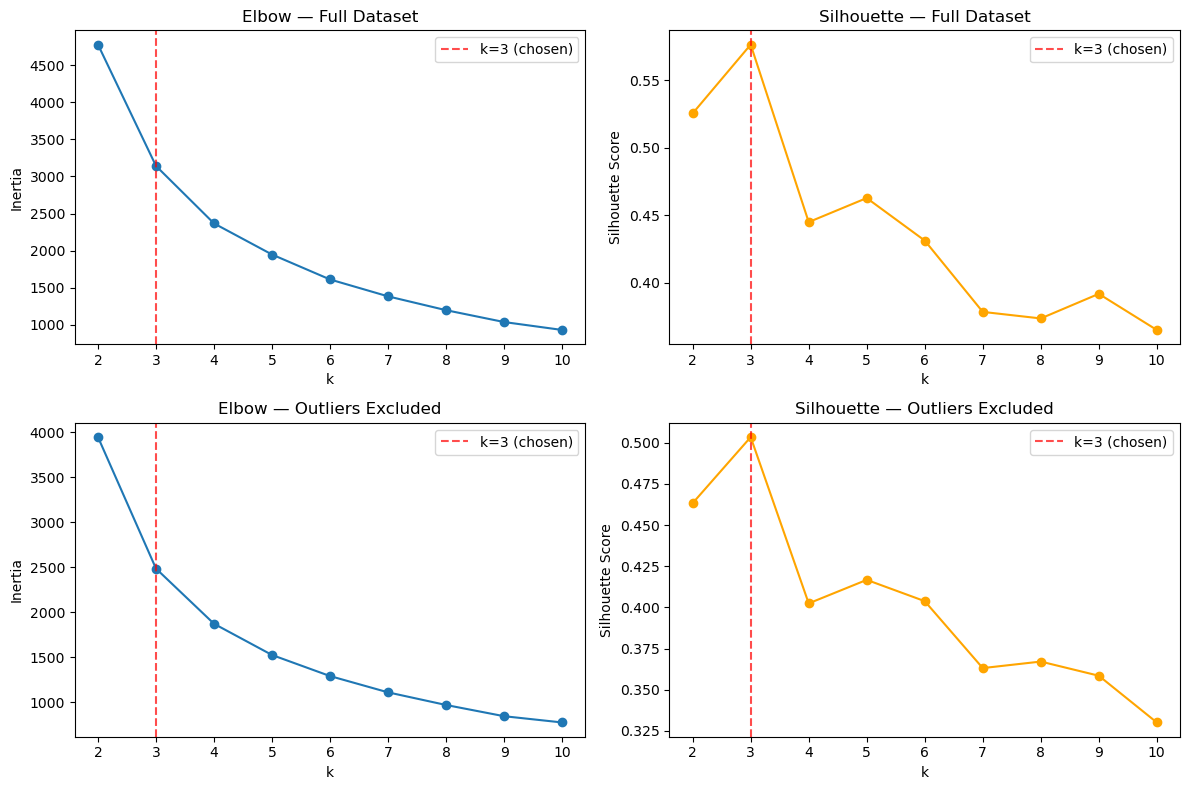

In [4]:
k_range = range(2, 11)

def compute_metrics(X_scaled, k_range):
    inertias, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, labels))
    return inertias, silhouettes

inertias_full, silhouettes_full = compute_metrics(X_full_scaled, k_range)
inertias_no_out, silhouettes_no_out = compute_metrics(X_no_outliers_scaled, k_range)

chosen_k = 3

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(list(k_range), inertias_full, marker="o")
axes[0, 0].axvline(x=chosen_k, color="red", linestyle="--", alpha=0.7, label=f"k={chosen_k} (chosen)")
axes[0, 0].set_title("Elbow — Full Dataset")
axes[0, 0].set_xlabel("k")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].legend()

axes[0, 1].plot(list(k_range), silhouettes_full, marker="o", color="orange")
axes[0, 1].axvline(x=chosen_k, color="red", linestyle="--", alpha=0.7, label=f"k={chosen_k} (chosen)")
axes[0, 1].set_title("Silhouette — Full Dataset")
axes[0, 1].set_xlabel("k")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].legend()

axes[1, 0].plot(list(k_range), inertias_no_out, marker="o")
axes[1, 0].axvline(x=chosen_k, color="red", linestyle="--", alpha=0.7, label=f"k={chosen_k} (chosen)")
axes[1, 0].set_title("Elbow — Outliers Excluded")
axes[1, 0].set_xlabel("k")
axes[1, 0].set_ylabel("Inertia")
axes[1, 0].legend()

axes[1, 1].plot(list(k_range), silhouettes_no_out, marker="o", color="orange")
axes[1, 1].axvline(x=chosen_k, color="red", linestyle="--", alpha=0.7, label=f"k={chosen_k} (chosen)")
axes[1, 1].set_title("Silhouette — Outliers Excluded")
axes[1, 1].set_xlabel("k")
axes[1, 1].set_ylabel("Silhouette Score")
axes[1, 1].legend()

print("Silhouette scores (full):", [round(s, 4) for s in silhouettes_full])
print("Silhouette scores (no outliers):", [round(s, 4) for s in silhouettes_no_out])


plt.tight_layout()
plt.show()

Silhouette peaks sharply at k=3 in both datasets, 0.5764 (full) and 0.5034
(outliers excluded), clearly ahead of every other k tested. The elbow
curves are smooth without a dramatic bend, so the silhouette score is what
actually decides this, exactly the role it was included for.

Two things are worth noting together. First, k=3 holding in both the full
dataset and the outlier-excluded one is a good sign: the optimal cluster
count isn't an artifact of the extreme values, it's a stable signal in the
core population too. Second, every silhouette score here (0.33-0.58) is
well below 1, normal for real-world retail data, where segments blend into
each other rather than forming tight, well-separated groups, and worth
noting so k=3 isn't read as "clusters are extremely distinct," only as "the
best relative separation among the k values tested."

**Decision: k=3** for both datasets, to be fit and interpreted in Section 4.
The (benign) `threadpoolctl` warning about OpenMP libraries is a runtime
environment notice, not a computation error, results were consistent and
complete.

## 4. Fitting k=3 and Profiling the Clusters

With k=3 chosen, we fit the final model on both feature sets and profile
each cluster by its average Recency, Frequency, and Monetary, translating
cluster numbers (0, 1, 2) into households a business stakeholder would
recognize. Cluster numbers are arbitrary integers assigned independently by each `KMeans.fit_predict()` call, so "cluster 0" in one run has no necessary relationship to "cluster 0" in the other; both profiles are ranked by mean `monetary` right after fitting, so cluster identity is established from data, not by assuming the label order carries meaning.

In [5]:
kmeans_full = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm["cluster"] = kmeans_full.fit_predict(X_full_scaled)

kmeans_no_out = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm_no_outliers["cluster"] = kmeans_no_out.fit_predict(X_no_outliers_scaled)

print("=== Full dataset — cluster profiles ===")
profile_full = rfm.groupby("cluster")[["recency", "frequency", "monetary"]].agg(["mean", "count"])
print(profile_full)

print("\n=== Outliers excluded — cluster profiles ===")
profile_no_out = rfm_no_outliers.groupby("cluster")[["recency", "frequency", "monetary"]].agg(["mean", "count"])
print(profile_no_out)

=== Full dataset — cluster profiles ===
            recency         frequency           monetary      
               mean count        mean count         mean count
cluster                                                       
0          3.674365   433  285.762125   433  8772.039700   433
1         19.705912  1996   75.245992  1996  2113.435155  1996
2        324.169014    71   22.760563    71   573.990423    71

=== Outliers excluded — cluster profiles ===
            recency         frequency           monetary      
               mean count        mean count         mean count
cluster                                                       
0         23.605596  1501   53.401732  1501  1453.101939  1501
1          7.604426   723  160.319502   723  4987.994675   723
2        329.264706    68   15.794118    68   433.321471    68


Rather than read cluster identity off the arbitrary integer labels, we rank each dataset's three clusters by mean `monetary`, low to high, and confirm that the same ranking also orders `recency` (decreasing) and `frequency` (increasing) — i.e. the "low value" cluster is genuinely low on every RFM dimension at once, not just on spend.

In [6]:
rank_order_full = profile_full[("monetary", "mean")].sort_values().index.tolist()
rank_order_no_out = profile_no_out[("monetary", "mean")].sort_values().index.tolist()

recency_by_rank_full = profile_full.loc[rank_order_full, ("recency", "mean")]
frequency_by_rank_full = profile_full.loc[rank_order_full, ("frequency", "mean")]
recency_by_rank_no_out = profile_no_out.loc[rank_order_no_out, ("recency", "mean")]
frequency_by_rank_no_out = profile_no_out.loc[rank_order_no_out, ("frequency", "mean")]

print("Full dataset — cluster labels ranked low to high value:", rank_order_full)
print("Outliers excluded — cluster labels ranked low to high value:", rank_order_no_out)

assert recency_by_rank_full.is_monotonic_decreasing
assert frequency_by_rank_full.is_monotonic_increasing
assert recency_by_rank_no_out.is_monotonic_decreasing
assert frequency_by_rank_no_out.is_monotonic_increasing
print("\nThe monetary-based rank also orders recency and frequency consistently in both datasets.")

Full dataset — cluster labels ranked low to high value: [2, 1, 0]
Outliers excluded — cluster labels ranked low to high value: [2, 0, 1]

The monetary-based rank also orders recency and frequency consistently in both datasets.


The two clusterings agree on one thing and disagree sharply on another.

**They agree on the "lost" segment.** The lowest-ranked cluster in both datasets is nearly identical: ~70 households, recency around 324–329 days, frequency around 16–23 baskets, monetary around $433–574. The next cell checks this directly at the household level, rather than only by comparing summary statistics that could coincidentally look similar for two different sets of households.

In [7]:
lowest_full = rank_order_full[0]
lowest_no_out = rank_order_no_out[0]

households_lowest_full = set(rfm.loc[rfm["cluster"] == lowest_full, "household_key"])
households_lowest_no_out = set(rfm_no_outliers.loc[rfm_no_outliers["cluster"] == lowest_no_out, "household_key"])

n_common = len(households_lowest_full & households_lowest_no_out)
n_union = len(households_lowest_full | households_lowest_no_out)

print(f"Lowest-value cluster — full dataset: {len(households_lowest_full)} households")
print(f"Lowest-value cluster — outliers excluded: {len(households_lowest_no_out)} households")
print(f"Households in both: {n_common} ({n_common / n_union:.1%} of their union)")

Lowest-value cluster — full dataset: 71 households
Lowest-value cluster — outliers excluded: 68 households
Households in both: 68 (95.8% of their union)


The overlap is near-total, confirming this is genuinely the same group of households in both runs, not a coincidental resemblance in aggregate statistics. This is expected on structural grounds too: the IQR outlier bounds computed in Section 2 are one-sided in practice (the lower bound is negative for both `frequency` and `monetary`, which can never occur), so outlier removal can only remove *high*-value households, never low-value ones — the "lost" group was never a candidate for exclusion, which is exactly why it stayed put while the boundary above it moved.

**They disagree sharply on the "high value" segment.** With outliers included, K-means carves out a small, extreme cluster: 433 households averaging $8,772 in spend and 286 baskets, clearly pulled toward the extreme monetary outliers identified in `02_rfm.ipynb`. With outliers excluded, the equivalent high-value cluster grows substantially in size (723 households, up from 433) but its average spend drops to $4,988, because without the extreme pull, K-means redraws the boundary to include households that were previously absorbed into the moderate middle cluster.

This is a textbook case of K-means' sensitivity to extreme values via Euclidean distance: a small number of very high spenders don't just form their own cluster, they distort where the boundary falls for everyone nearby. Neither result is "wrong"; they're answering slightly different questions. The outlier-included version isolates an extreme elite tier; the outlier-excluded version gives a more representative picture of "who's actually a high-value customer" among typical shoppers.

## 5. Visual Comparison

A scatter plot of `frequency` vs `monetary`, colored by cluster, makes the
boundary-shifting effect from Section 4 visible directly, rather than only
inferred from summary statistics. Points are colored by each dataset's own monetary rank (Section 4), not by the raw cluster label, so the same color means the same relative tier — lowest, middle, or highest average spend — in both panels; coloring by the raw label would make the two panels' colors mean different things, since K-means assigns labels independently in each run.

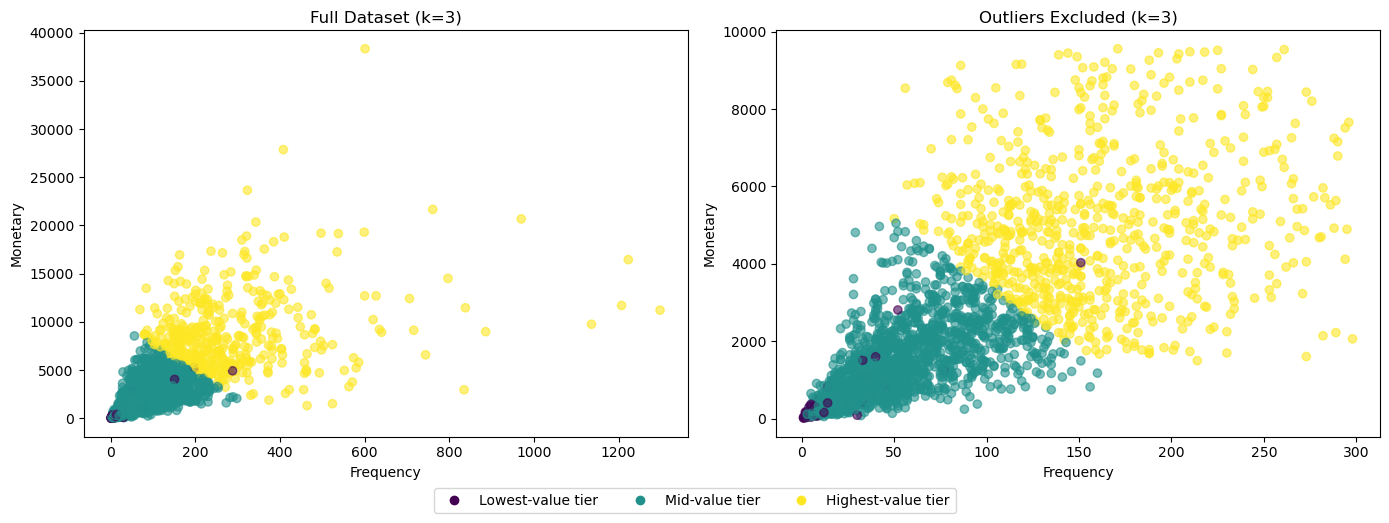

In [8]:
tier_colors = [plt.cm.viridis(0.0), plt.cm.viridis(0.5), plt.cm.viridis(1.0)]
tier_labels = ["Lowest-value tier", "Mid-value tier", "Highest-value tier"]

rank_map_full = {label: rank for rank, label in enumerate(rank_order_full)}
rank_map_no_out = {label: rank for rank, label in enumerate(rank_order_no_out)}

rank_full = rfm["cluster"].map(rank_map_full)
rank_no_out = rfm_no_outliers["cluster"].map(rank_map_no_out)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(rfm["frequency"], rfm["monetary"], c=rank_full,
                cmap="viridis", vmin=0, vmax=2, alpha=0.6)
axes[0].set_title("Full Dataset (k=3)")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Monetary")

axes[1].scatter(rfm_no_outliers["frequency"], rfm_no_outliers["monetary"], c=rank_no_out,
                cmap="viridis", vmin=0, vmax=2, alpha=0.6)
axes[1].set_title("Outliers Excluded (k=3)")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Monetary")

legend_handles = [
    plt.Line2D([0], [0], marker="o", linestyle="", color=tier_colors[i], label=tier_labels[i])
    for i in range(3)
]
fig.legend(handles=legend_handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()

from pathlib import Path
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../outputs/figures/03_cluster_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

The visual comparison makes the boundary-distortion effect obvious in a way
the summary tables only hinted at. Notice first the axis scale itself: the
full dataset's y-axis reaches $40,000, while the outlier-excluded version
tops out around $10,000, a 4x difference in resolution. That's not just a
plotting detail; it means that in the full-dataset view, the 92% of
"typical" households are visually compressed into a small corner of the
chart, making it harder to see any structure among them at all.

The outlier-excluded plot (right) shows a much cleaner picture: two main
color bands separated along a fairly clean diagonal, consistent with the
moderate (1,501 households) vs. high-value (723 households) split from
Section 4, plus a small third group tucked into the low corner. The
full-dataset plot (left) is visually messier, with less geometrically clean
boundaries between colors, and a handful of extreme points scattered far
from the main mass. This matches Section 4's conclusion directly: a small
number of extreme values don't just get their own cluster, they distort
where K-means draws the line for everyone near them.

## 6. Final Segmentation

We combine the outlier-excluded clustering (3 algorithmic clusters) with the
208 excluded outlier households as a fourth, manually-defined "Elite" tier,
following the recommendation from Section 5: the outlier-excluded version
better represents the typical customer, while the outliers themselves are
preserved as a separate, explicit category rather than discarded or forced
into one of the 3 algorithmic clusters.

Cluster numbers are translated into business-readable names using the monetary-based rank order established in Section 4, not by re-reading the profile table and hardcoding which integer maps to which name — a hardcoded mapping would silently mislabel every household if a future rerun assigned the same clusters to different integers.

The lowest tier is named "Inactive" here rather than "Lost": `02_rfm.ipynb`'s rule-based segmentation already uses "Lost" for a much larger, differently-defined group (549 households, 22% of the base). Reusing the same word for an unrelated 68-household clustering-based group, in a table that will carry both columns side by side, invites exactly the kind of confusion this project's evidence-first approach is meant to avoid.

In [9]:
value_tier_names = ["Inactive", "Moderate", "High Value"]  # low to high, by the verified monetary rank
cluster_names = dict(zip(rank_order_no_out, value_tier_names))
print(cluster_names)

rfm_no_outliers["final_segment"] = rfm_no_outliers["cluster"].map(cluster_names)

rfm["final_segment"] = rfm["household_key"].map(
    rfm_no_outliers.set_index("household_key")["final_segment"]
)
rfm.loc[rfm["final_segment"].isna(), "final_segment"] = "Elite / Outlier"

final_summary = (
    rfm.groupby("final_segment")
    .agg(n_households=("household_key", "count"),
         avg_recency=("recency", "mean"),
         avg_frequency=("frequency", "mean"),
         avg_monetary=("monetary", "mean"))
    .sort_values("avg_monetary", ascending=False)
)
final_summary["pct_households"] = (final_summary["n_households"] / len(rfm) * 100).round(1)

assert final_summary["n_households"].sum() == len(rfm)
final_summary

{2: 'Inactive', 0: 'Moderate', 1: 'High Value'}


,n_households,avg_recency,avg_frequency,avg_monetary,pct_households
final_segment,,,,,
Elite / Outlier,208,2.980769,376.927885,10771.976250,8.3
High Value,723,7.604426,160.319502,4987.994675,28.9
Moderate,1501,23.605596,53.401732,1453.101939,60.0
Inactive,68,329.264706,15.794118,433.321471,2.7


`cluster_names` was built from the verified rank order, not read off by eye: the lowest-monetary cluster (recency 329, monetary $433) → Inactive, the middle one (recency 23.6, monetary $1,453) → Moderate, the highest (recency 7.6, monetary $4,988) → High Value. All 208+723+1501+68 = 2,500 households are accounted for (the cell asserts it).

The final segmentation makes business sense end to end: **Elite/Outlier**
leads on every metric, $10,772 average spend, 377 average baskets, and just
3 days average recency, exactly the profile expected of the most valuable
tier, now preserved as its own explicit category instead of distorting the
boundary of the algorithmic clusters. **High Value** (723 households, 29%)
and **Moderate** (1,501 households, 60%) form the bulk of the customer base
with a clear gap between them in both frequency and spend. **Inactive** (68 households, 2.7%) is the smallest group, infrequent, high-recency households; the household-level overlap check in Section 4 (not just similar-looking averages) confirmed the full and outlier-excluded clusterings independently converge on almost exactly the same households here, reinforcing that this is a genuinely stable segment, not an artifact of one particular run — and, structurally, not one the outlier-removal step could have touched in the first place.

### 6.1 Persisting the Final Segmentation

We save `rfm`, now including the final segmentation, as a table in PostgreSQL, so `04_retention_cohorts.ipynb` and `05_campaigns_and_coupons.ipynb` can load it independently, consistent with how `rfm_household` was persisted at the end of `02_rfm.ipynb`. `final_segment` is the column those notebooks should use.

The raw `cluster` column from Section 4 is not persisted as-is: it holds the *full-dataset* K-means labels, the clustering Section 4 showed is distorted by outliers and explicitly superseded by `final_segment`. Persisting it under its original, unqualified name would let a future notebook mistake it for the recommended segmentation. It is kept, since it is a real diagnostic result worth being able to trace, but renamed to `cluster_full_data_rank` and stored as the monetary-based rank (0 = lowest, 2 = highest) rather than the arbitrary sklearn label, so it means the same thing on any rerun. A primary key is added after the load, and the persisted row count and column set are verified against the source DataFrame via SQL, not just assumed from `to_sql()` completing without error.

In [10]:
rfm["cluster_full_data_rank"] = rfm["cluster"].map(rank_map_full)
rfm_to_persist = rfm.drop(columns=["cluster"])

with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS rfm_segmented;"))

rfm_to_persist.to_sql("rfm_segmented", engine, if_exists="append", index=False)

with engine.begin() as conn:
    conn.execute(text("ALTER TABLE rfm_segmented ADD PRIMARY KEY (household_key);"))
    count = conn.execute(text("SELECT COUNT(*) FROM rfm_segmented")).scalar()
    n_columns = conn.execute(text("""
        SELECT COUNT(*) FROM information_schema.columns
        WHERE table_schema = 'public' AND table_name = 'rfm_segmented'
    """)).scalar()

print(f"rfm_segmented: {count} rows, {n_columns} columns persisted.")
assert count == len(rfm_to_persist)
assert n_columns == rfm_to_persist.shape[1]

rfm_segmented: 2500 rows, 14 columns persisted.


## 7. Final Segmentation Visualization

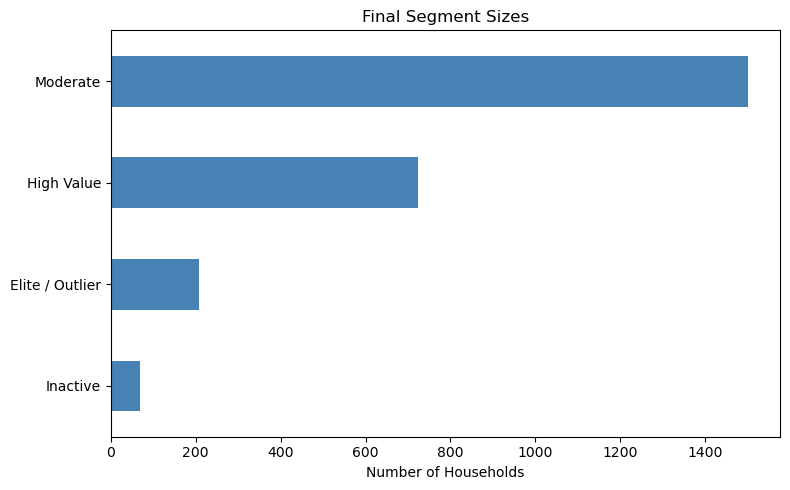

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
final_summary["n_households"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Number of Households")
ax.set_ylabel("")
ax.set_title("Final Segment Sizes")
plt.tight_layout()
plt.show()

The segment sizes form the shape typical of a real customer base: the
majority sits in the Moderate tier, with a substantial High Value group
below it, and both extremes, Elite/Outlier and Lost, represent smaller
minorities. No segment is empty or negligibly small enough to question its
usefulness for targeting.

## 8. Conclusion

This notebook set out to answer the question `02_rfm.ipynb` left open: do
natural customer segments exist beyond what simple RFM quartiles already
show?

The answer is yes, and the evidence is concrete rather than assumed. K-means
with k=3 (chosen via silhouette score, not guessed — Section 3) found a
stable low-value segment, confirmed at the household level (Section 4) to be
nearly the same group of households whether outliers are included or not,
and a clear separation between Moderate and High
Value households that the original quartile-based rules in `02_rfm.ipynb`
couldn't cleanly produce (recall the `At Risk` anomaly from that notebook's
Section 5, where fixed thresholds produced a sub-group whose raw averages
didn't match its own name).

Running the full pipeline twice, with and without the 208 outliers flagged
in `02_rfm.ipynb`, surfaced a concrete, textbook demonstration of K-means'
sensitivity to extreme values: outliers didn't just form their own cluster,
they measurably shifted where the algorithm drew the boundary for
everyone else (Section 4-5). Rather than pick one version and discard the
other, the final segmentation combines both: the outlier-excluded clustering
(Inactive, Moderate, High Value) represents the typical customer accurately, and
the 208 outliers are preserved as an explicit "Elite/Outlier" tier rather
than being forced into a cluster they'd distort or silently dropped.

The final segmentation, Elite/Outlier (8.3%), High Value (28.9%), Moderate
(60.0%), Inactive (2.7%), is grounded in validated evidence at every step: a
data-driven k, a cluster-naming scheme derived from verified ranks rather than hardcoded integers, cross-checked cluster stability at the household level, and an explicit, documented decision about how to handle outliers rather than an implicit one. This
closes the segmentation phase of the project; the next notebooks
(`04_retention_cohorts.ipynb` and `05_Campaigns_and_Coupons.ipynb`) can build
on `rfm` and its `final_segment` column with confidence in how it was
constructed.